# code_193 · Counterfactual evaluation depends on support and design

**Book:** section 36.6. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_193).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7793;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7793


<a id="supported-policy-and-causal-assessment"></a>
 ## Fit nuisance responses elsewhere and assess a locked policy
 Generate 3,000 source and 1,500 independent logged contexts. Treatment propensity is known by design, clipped between 0.05 and 0.95. Potential response means are mu0=0.4+0.5x and mu1=0.1−0.3x; higher response is better. Assigned action follows propensity and observed response adds independent noise of standard deviation 0.5. Fit separate source-only Ridge response models, then lock the action with larger fitted mean. Use independent logs for ordinary IPS and doubly robust policy-value estimates, and a doubly robust ATE score. Compare with known finite-cohort mean outcomes and regret only as simulator audit. A 600-resample observation bootstrap quantifies conditional logged-score variation, not nuisance-training or unmeasured-confounding uncertainty.

 A second logging fixture deterministically selects action 1 only when x>0. Compute unsupported target mass and refuse a full-policy IPS estimate whenever it is nonzero. Do not clip zero propensity into invented evidence. Weighted mean context balance is a diagnostic of the supported design, not proof that an observational study has no hidden confounder.


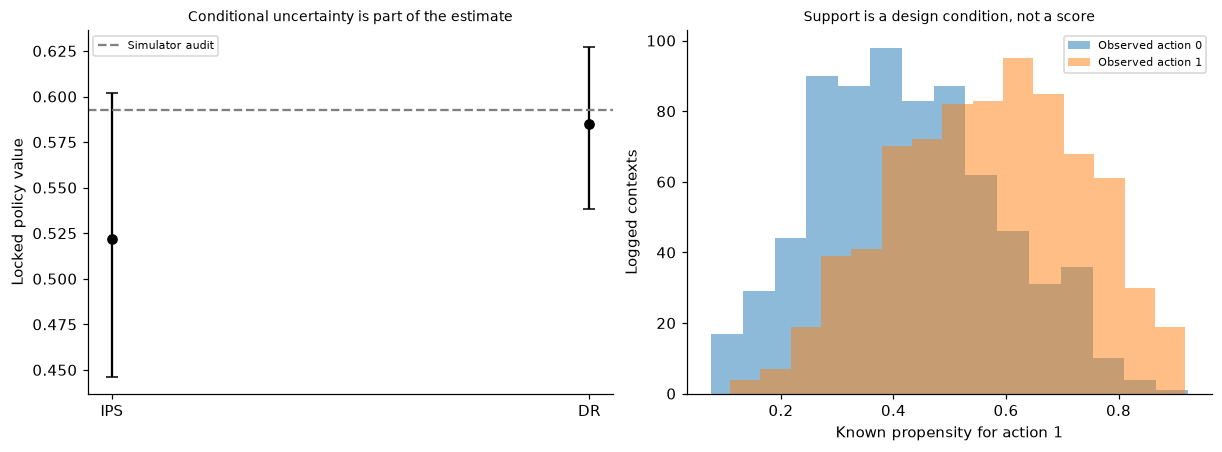

In [2]:
from sklearn.linear_model import Ridge
def logs(n):
    x=rng.normal(size=n);p=np.clip(expit(.8*x),.05,.95);a=rng.binomial(1,p);m0=.4+.5*x;m1=.1-.3*x;y=np.where(a==1,m1,m0)+rng.normal(scale=.5,size=n);return x,p,a,y,m0,m1
xs,ps,as_,ys,_,_=logs(3000);x,p,a,y,m0,m1=logs(1500);models=[Ridge(alpha=1).fit(xs[as_==k,None],ys[as_==k]) for k in [0,1]];mhat=np.column_stack([m.predict(x[:,None]) for m in models]);policy=np.argmax(mhat,axis=1);pa=np.where(a==1,p,1-p);chosen=mhat[np.arange(1500),policy];factual=mhat[np.arange(1500),a];match=(a==policy);ips=match*y/pa;dr=chosen+match*(y-factual)/pa;ate=mhat[:,1]-mhat[:,0]+a*(y-mhat[:,1])/p-(1-a)*(y-mhat[:,0])/(1-p);truth=float(np.mean(np.where(policy==1,m1,m0)));oracle=np.maximum(m0,m1);regret=float(np.mean(oracle-np.where(policy==1,m1,m0)));draws=rng.integers(0,1500,(600,1500));ci={name:np.quantile(score[draws].mean(1),[.025,.975]).tolist() for name,score in [('IPS',ips),('DR',dr),('ATE',ate)]};det_action=(x>0).astype(int);unsupported=float(np.mean(policy!=det_action));full_value=None if unsupported else float(np.mean(y));weighted_balance=float(np.sum(a*x/p)/np.sum(a/p)-np.sum((1-a)*x/(1-p))/np.sum((1-a)/(1-p)))
assert np.all((p>=.05)&(p<=.95));assert unsupported>0 and full_value is None;assert np.all(oracle>=np.where(policy==1,m1,m0));RESULTS.update(source_contexts=3000,assessment_contexts=1500,policy_value_IPS=float(ips.mean()),policy_value_DR=float(dr.mean()),policy_value_simulator_audit=truth,policy_regret_simulator_audit=regret,ATE_DR=float(ate.mean()),ATE_simulator_audit=float(np.mean(m1-m0)),conditional_bootstrap_CIs=ci,deterministic_logging_unsupported_target_fraction=unsupported,unsupported_full_policy_value=full_value,weighted_context_mean_difference=weighted_balance,unweighted_context_mean_difference=float(x[a==1].mean()-x[a==0].mean()))
fig,axes=plt.subplots(1,2,figsize=(11,4));means=[ips.mean(),dr.mean()];interval=np.array([ci['IPS'],ci['DR']]);axes[0].errorbar([0,1],means,yerr=np.array([means-interval[:,0],interval[:,1]-means]),fmt='o',color='black',capsize=4);axes[0].axhline(truth,color='.5',linestyle='--',label='Simulator audit');axes[0].set(xticks=[0,1],xticklabels=['IPS','DR'],ylabel='Locked policy value',title='Conditional uncertainty is part of the estimate');axes[0].legend(fontsize=7);axes[1].hist(p[a==0],bins=15,alpha=.5,label='Observed action 0');axes[1].hist(p[a==1],bins=15,alpha=.5,label='Observed action 1');axes[1].set(xlabel='Known propensity for action 1',ylabel='Logged contexts',title='Support is a design condition, not a score');axes[1].legend(fontsize=7);plt.show()


<a id="executed-control-and-constraints"></a>
 ## Execute identical-disturbance rollouts and retain violations
 A separate original 20-step thermal-load simulator evaluates three fixed controllers on 200 independent trajectories. State evolves as 0.9s+0.5load−0.6action+noise; action is 0 or 1 and incurs cost 0.2. Per-step reward is −s_next²−0.2action. The state constraint is s_next≤1.5. Controllers act never, act above state 0.8, or always. Use identical pre-generated load and disturbance arrays for paired policies; no observed outcome chooses a controller. Report trajectory return, fraction with any violation, maximum violation and average actions. A high average reward does not override a failed constraint; finite simulation under a declared law cannot certify a physical controller.


,mean_return,any_violation_fraction,maximum_violation,mean_actions_per_episode
Never,-218.292946,1.00,3.831016,0.000
State trigger,-20.304078,0.09,0.149180,12.485
Always,-14.194143,0.00,0.000000,20.000


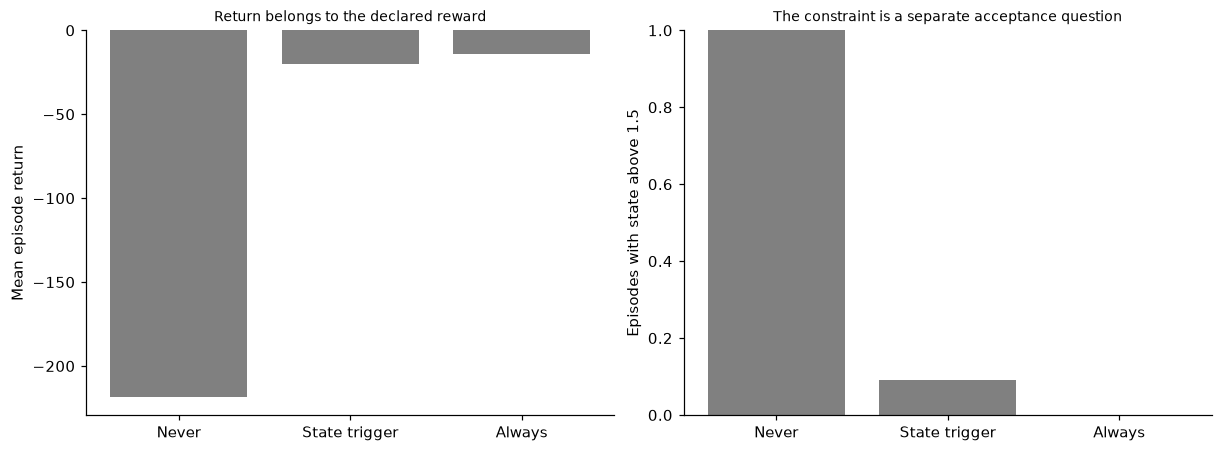

In [3]:
trials=200;steps=20;loads=rng.uniform(.5,1.5,(trials,steps));noise=rng.normal(scale=.12,size=(trials,steps));initial=rng.uniform(0,.5,trials);control={}
for name,rule in [('Never',lambda s:np.zeros_like(s)),('State trigger',lambda s:(s>.8).astype(float)),('Always',lambda s:np.ones_like(s))]:
    state=initial.copy();rewards=[];states=[];actions=[]
    for t in range(steps):
        action=rule(state);state=.9*state+.5*loads[:,t]-.6*action+noise[:,t];rewards.append(-state**2-.2*action);states.append(state.copy());actions.append(action.copy())
    states=np.array(states).T;actions=np.array(actions).T;ret=np.array(rewards).sum(0);control[name]={'mean_return':float(ret.mean()),'any_violation_fraction':float(np.mean(np.any(states>1.5,axis=1))),'maximum_violation':float(np.maximum(states-1.5,0).max()),'mean_actions_per_episode':float(actions.sum(1).mean()),'trajectory_returns':ret.tolist()};assert len(ret)==200 and np.isfinite(states).all()
assert all(0<=v['any_violation_fraction']<=1 for v in control.values());RESULTS.update(control_trials=200,control_steps=20,control_scores=control,shared_disturbances_across_controllers=True);display(pd.DataFrame([{k:v for k,v in row.items() if k!='trajectory_returns'} for row in control.values()],index=list(control)));fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(3);names=list(control);axes[0].bar(xx,[control[k]['mean_return'] for k in names],color='.5');axes[0].set(xticks=xx,xticklabels=names,ylabel='Mean episode return',title='Return belongs to the declared reward');axes[1].bar(xx,[control[k]['any_violation_fraction'] for k in names],color='.5');axes[1].set(xticks=xx,xticklabels=names,ylim=(0,1),ylabel='Episodes with state above 1.5',title='The constraint is a separate acceptance question');plt.show()


In [4]:
summary={'example_id':'code_193','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['independent logged bandit IPS and doubly robust values with simulator audit', 'actual source-fitted nuisance outcomes and supported ATE score', 'unsupported deterministic logging explicitly refuses full policy value', 'executed sequential controllers report return regret and constraint violations'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["independent logged bandit IPS and doubly robust values with simulator audit", "actual source-fitted nuisance outcomes and supported ATE score", "unsupported deterministic logging explicitly refuses full policy value", "executed sequential controllers report return regret and constraint violations"], "elapsed_seconds": 0.298, "example_id": "code_193", "hardware": "Darwin arm64 CPU", "results": {"ATE_DR": -0.334247963577735, "ATE_simulator_audit": -0.2964895306826522, "assessment_contexts": 1500, "conditional_bootstrap_CIs": {"ATE": [-0.3990657206933821, -0.27589174695669666], "DR": [0.5381857068647917, 0.6272443373077776], "IPS": [0.44605700598517595, 0.6019950388542279]}, "control_scores": {"Always": {"any_violation_fraction": 0.0, "maximum_violation": 0.0, "mean_actions_per_episode": 20.0, "mean_return": -14.19414328095969, "trajectory_returns": [-27.545780367580488, -15.858427356076174, -7.0532807273474285, -17.36674163979964, -12.97